# Day 9-11 — Customer Churn: KNN vs Naive Bayes vs Decision Tree vs Random Forest vs Logistic Regression

## 1. Load data; `churned` is y; drop `churned` and `customer_id` from X

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

df = pd.read_excel('customer_churn_classification.xlsx', sheet_name='Customer data')
y = df['churned']
X = df.drop(columns=['churned', 'customer_id'])
print(df.shape); print(X.isna().sum().sum(), 'missing values'); print(y.value_counts())

(500, 12)
0 missing values
churned
0    360
1    140
Name: count, dtype: int64


## 2. Stratified 80/20 split and class counts

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train churned:', y_train.sum(), 'of', len(y_train), '| Test churned:', y_test.sum(), 'of', len(y_test))

Train churned: 112 of 400 | Test churned: 28 of 100


## 3-4. Five models (scaler inside a Pipeline for KNN and Logistic Regression, so it is fitted on training data only)

In [3]:
models = {
 'KNN': Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))]),
 'Gaussian NB': GaussianNB(),
 'Decision Tree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=42),
 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
 'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))]),
}
for m in models.values(): m.fit(X_train, y_train)

## 5. Test metrics and confusion matrices

In [4]:
rows=[]; cms={}
for n,m in models.items():
    p = m.predict(X_test); cm = confusion_matrix(y_test, p); cms[n]=cm
    rows.append(dict(model=n, accuracy=accuracy_score(y_test,p), precision=precision_score(y_test,p,zero_division=0),
                     recall=recall_score(y_test,p), f1=f1_score(y_test,p), TN=cm[0,0], FP=cm[0,1], FN=cm[1,0], TP=cm[1,1]))
res = pd.DataFrame(rows).set_index('model').round(3); res

                     accuracy  precision  recall     f1  TN  FP  FN  TP
model                                                                  
KNN                      0.75      0.565   0.464  0.510  62  10  15  13
Gaussian NB              0.78      0.600   0.643  0.621  60  12  10  18
Decision Tree            0.74      0.545   0.429  0.480  62  10  16  12
Random Forest            0.83      0.720   0.643  0.679  65   7  10  18
Logistic Regression      0.82      0.656   0.750  0.700  61  11   7  21

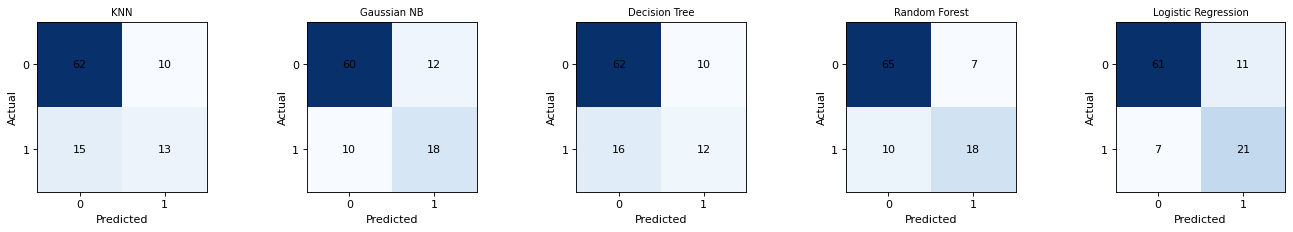

In [5]:
fig, ax = plt.subplots(1,5,figsize=(17,3))
for a,(n,cm) in zip(ax,cms.items()):
    a.imshow(cm, cmap='Blues'); a.set_title(n, fontsize=9)
    for i in range(2):
        for j in range(2): a.text(j,i,cm[i,j],ha='center',va='center')
    a.set_xticks([0,1]); a.set_yticks([0,1]); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 6. Comparison

In [6]:
print('Most churners caught (highest recall):', res['recall'].idxmax(), res['recall'].max())
print('Fewest false alarms (lowest FP):', res['FP'].idxmin(), res['FP'].min())
print('Best precision:', res['precision'].idxmax(), res['precision'].max())

Most churners caught (highest recall): Logistic Regression 0.75
Fewest false alarms (lowest FP): Random Forest 7
Best precision: Random Forest 0.72


The model with the highest recall catches the most customers who cancel, while the model with the lowest FP count (and highest precision) wastes the least retention budget. These goals usually point to **different** models: catching more churners means flagging more customers, which raises false alarms. So the same model is not necessarily the right choice for both goals; the decision depends on the cost of a missed churner versus the cost of an unnecessary offer.

## 7. What each model learned

In [7]:
# KNN: compare K values using 5-fold CV on training data only
from sklearn.model_selection import cross_val_score
for k in [1,3,5,7,11,15,21]:
    s = cross_val_score(Pipeline([('s',StandardScaler()),('k',KNeighborsClassifier(n_neighbors=k))]), X_train, y_train, cv=5, scoring='f1').mean()
    print(f'K={k:2d}  CV F1={s:.3f}')

K= 1  CV F1=0.546
K= 3  CV F1=0.581
K= 5  CV F1=0.556
K= 7  CV F1=0.518
K=11  CV F1=0.460
K=15  CV F1=0.406
K=21  CV F1=0.377


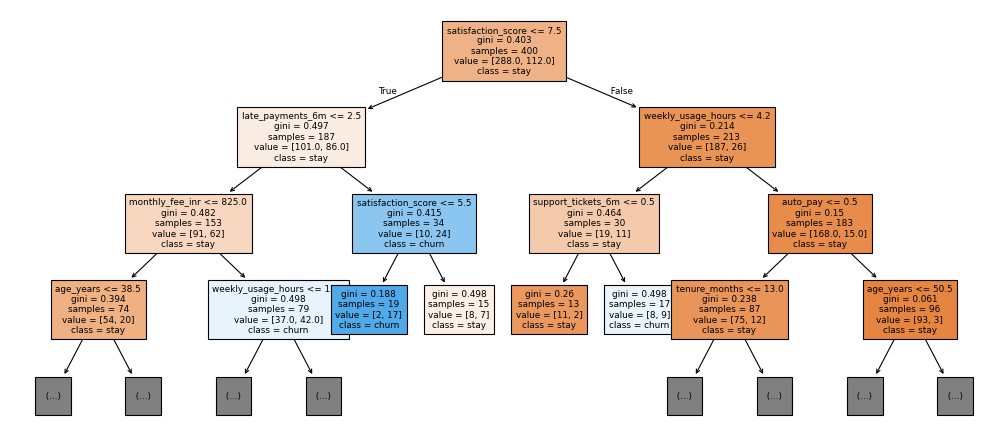

In [8]:
# Small decision tree
plt.figure(figsize=(16,7)); plot_tree(models['Decision Tree'], feature_names=X.columns, class_names=['stay','churn'], filled=True, max_depth=3, fontsize=8); plt.show()

weekly_usage_hours    0.189003
satisfaction_score    0.163018
tenure_months         0.125227
monthly_fee_inr       0.114832
age_years             0.110697
dtype: float64
weekly_usage_hours   -0.779512
support_tickets_6m    0.753621
late_payments_6m      0.702986
competitor_offer      0.665575
monthly_fee_inr       0.546110
dtype: float64


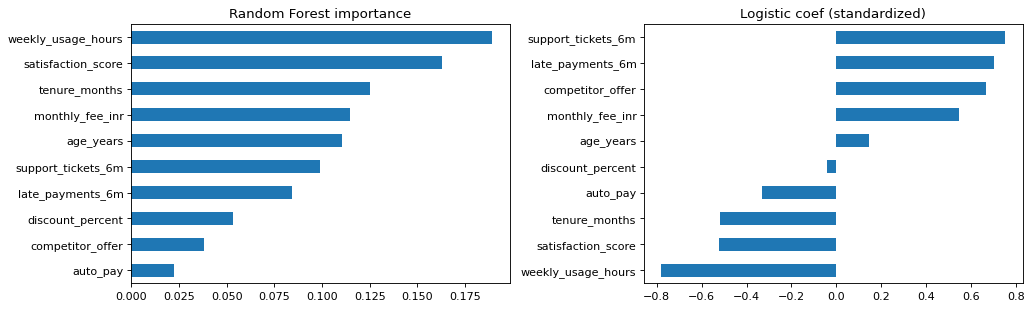

In [9]:
# Random forest importances and logistic regression coefficients
imp = pd.Series(models['Random Forest'].feature_importances_, index=X.columns).sort_values()
coef = pd.Series(models['Logistic Regression'].named_steps['lr'].coef_[0], index=X.columns).sort_values()
fig,ax=plt.subplots(1,2,figsize=(13,4)); imp.plot.barh(ax=ax[0],title='Random Forest importance'); coef.plot.barh(ax=ax[1],title='Logistic coef (standardized)'); plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).head(5)); print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(5))

## 8. Recommendation

In [10]:
best = res['recall'].idxmax(); bestf1 = res['f1'].idxmax()
print(f'Highest recall: {best}; highest F1: {bestf1}')

Highest recall: Logistic Regression; highest F1: Logistic Regression


For a retention campaign, missing a churner is usually costlier than sending an offer to a customer who would have stayed, so I would pick the model with the best **recall at acceptable precision**, judged mainly by F1 and recall rather than accuracy (churn is the minority class, so accuracy flatters models that predict 'stay'). Logistic Regression is a strong practical choice because its probabilities let the business tune the threshold (lower it to reach more at-risk customers) and its coefficients are explainable to the retention team. Random Forest is the alternative if it clearly beats it on F1. Final choice should be confirmed with cross-validation and a threshold chosen from campaign costs.